In [1]:
import numpy, scipy, sklearn
print(numpy.__version__, scipy.__version__, sklearn.__version__)

1.26.4 1.13.1 1.5.1


In [2]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE

# Load and clean (change the path if your CSV is elsewhere)
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df = df.drop_duplicates()
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Encode
for c in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
    df[c] = df[c].map({"Yes": 1, "No": 0})
df["gender"] = df["gender"].map({"Male": 1, "Female": 0})
df_enc = pd.get_dummies(df, drop_first=True)

X = df_enc.drop("Churn", axis=1)
y = df_enc["Churn"]

# Split, scale, SMOTE
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)

print("NaNs in X_train:", X_train.isnull().sum().sum())
print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_sm.value_counts().to_dict())
print("Feature count:", X.shape[1])

NaNs in X_train: 0
Before SMOTE: {0: 4131, 1: 1485}
After SMOTE: {1: 4131, 0: 4131}
Feature count: 30


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000), {
        "C": [0.01, 0.1, 1, 10]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=42), {
        "max_depth": [3, 5, 7, 10], "min_samples_split": [2, 10, 20]}),
    "Random Forest": (RandomForestClassifier(random_state=42), {
        "n_estimators": [100, 200, 300], "max_depth": [5, 10, None],
        "min_samples_split": [2, 5, 10]}),
    "XGBoost": (XGBClassifier(eval_metric="logloss", random_state=42), {
        "n_estimators": [100, 200, 300], "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.05, 0.1]}),
}

results, best_models = [], {}
for name, (model, params) in models.items():
    search = RandomizedSearchCV(model, params, n_iter=8, cv=5,
                                scoring="f1", random_state=42, n_jobs=-1)
    search.fit(X_train_sm, y_train_sm)
    best = search.best_estimator_
    best_models[name] = best
    pred = best.predict(X_test)
    prob = best.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })
    print(name, "best params:", search.best_params_)

results_df = pd.DataFrame(results).round(3).set_index("Model")
print(results_df)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:320: UserWarning: The total space of parameters 4 is smaller than n_iter=8. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Logistic Regression best params: {'C': 1}
Decision Tree best params: {'min_samples_split': 2, 'max_depth': 10}
Random Forest best params: {'n_estimators': 100, 'min_samples_split': 5, 'max_depth': None}
XGBoost best params: {'n_estimators': 300, 'max_depth': 7, 'learning_rate': 0.05}
                     Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                           
Logistic Regression     0.747      0.516   0.694  0.592    0.828
Decision Tree           0.729      0.492   0.726  0.586    0.763
Random Forest           0.767      0.554   0.624  0.587    0.823
XGBoost                 0.769      0.554   0.664  0.604    0.822


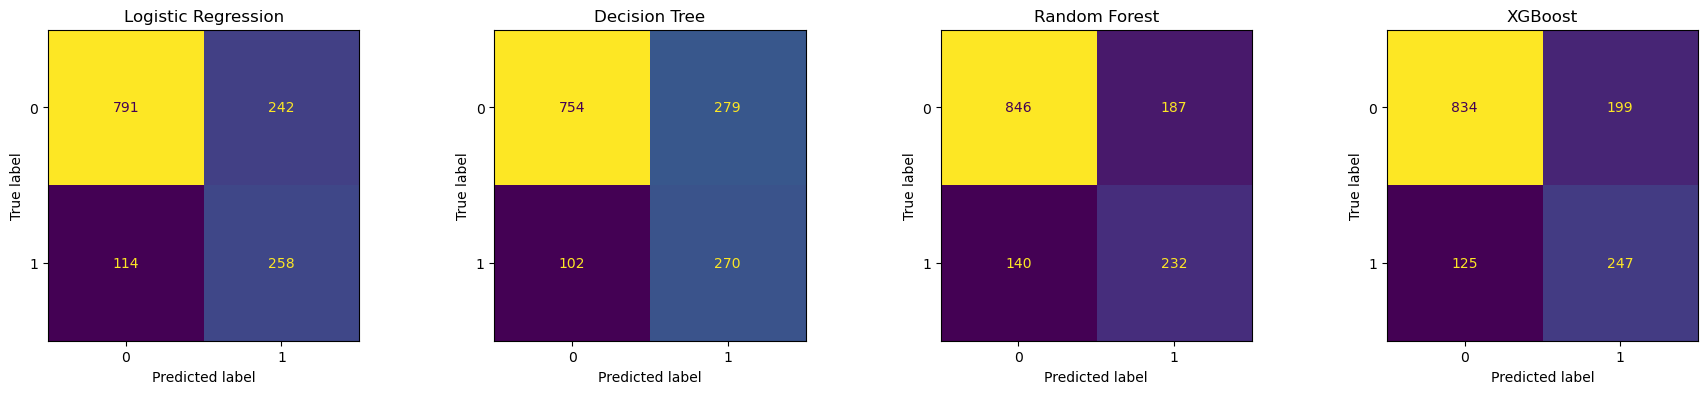

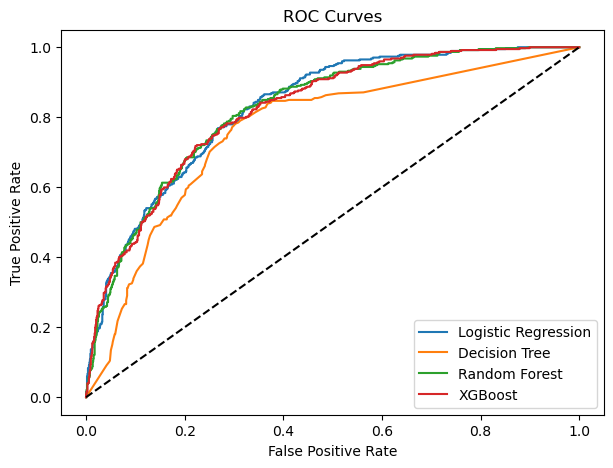

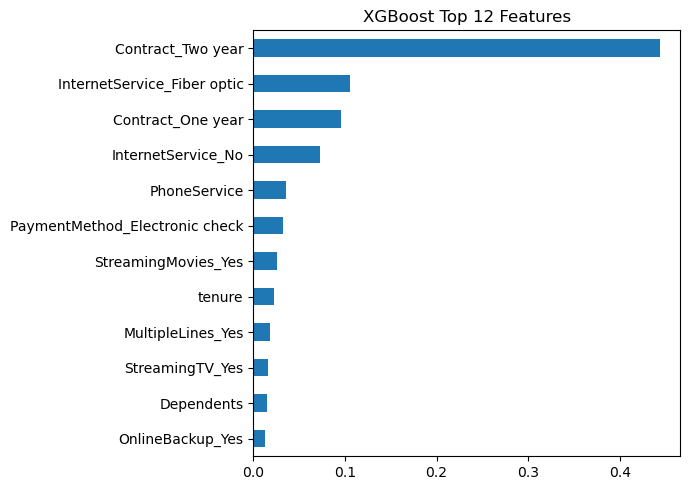

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt
import pandas as pd

# Confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, best_models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# ROC curves
plt.figure(figsize=(7, 5))
for name, m in best_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend()
plt.show()

# XGBoost feature importance (top 12)
imp = pd.Series(best_models["XGBoost"].feature_importances_, index=X.columns)
imp.nlargest(12).sort_values().plot(kind="barh", figsize=(7, 5),
                                    title="XGBoost Top 12 Features")
plt.tight_layout()
plt.show()

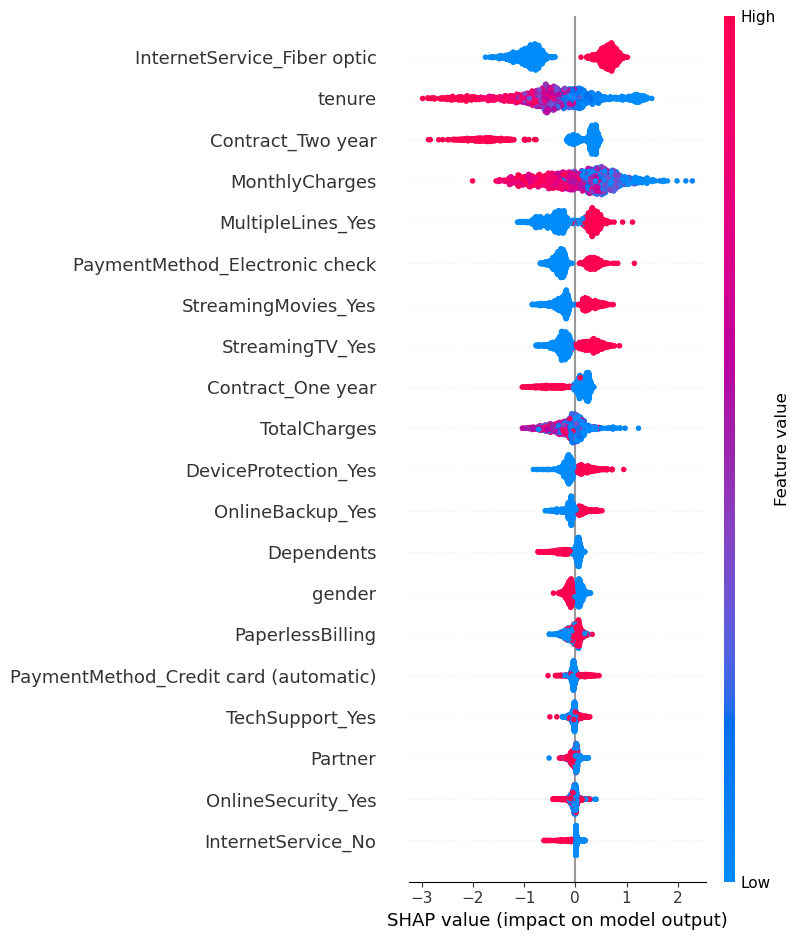

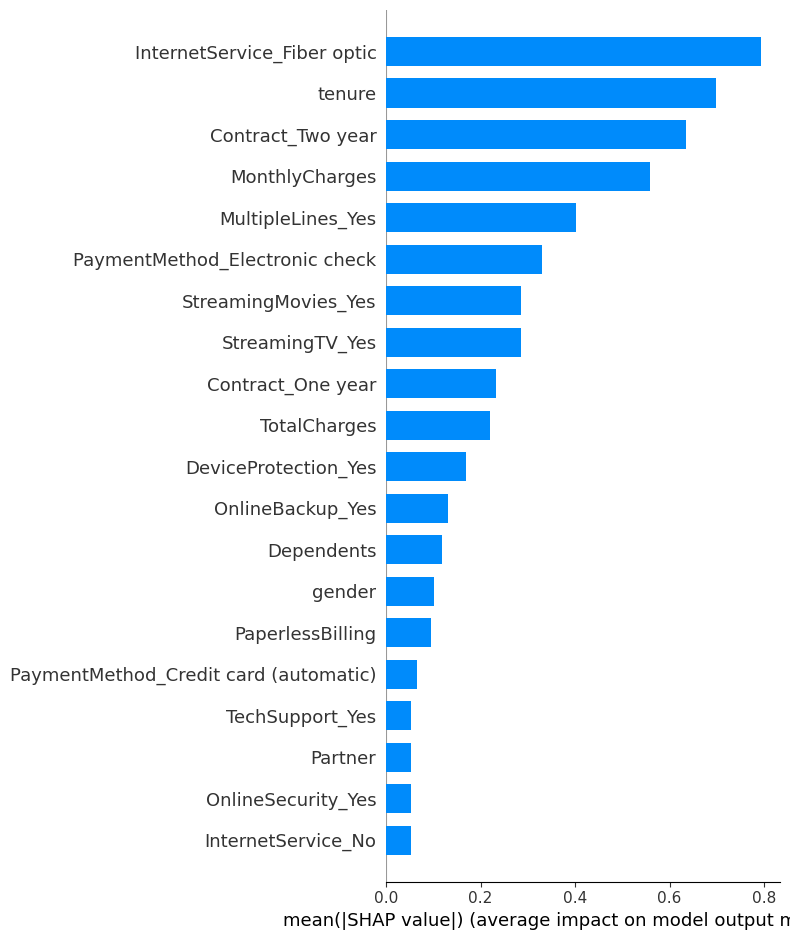

In [5]:
import shap

explainer = shap.TreeExplainer(best_models["XGBoost"])
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=True)
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)

In [6]:
import joblib

# Save the model, scaler and column order (needed later for the app)
joblib.dump(best_models["XGBoost"], "churn_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "columns.pkl")

# Flag at-risk customers from the test set
model = best_models["XGBoost"]
risk = X_test.copy()
risk["Churn_Probability"] = model.predict_proba(X_test)[:, 1]
risk["Actual_Churn"] = y_test.values
risk["Risk_Level"] = pd.cut(risk["Churn_Probability"],
                            bins=[0, 0.4, 0.7, 1.0],
                            labels=["Low", "Medium", "High"])

print(risk["Risk_Level"].value_counts())
print(risk.sort_values("Churn_Probability", ascending=False)
          [["Churn_Probability", "Risk_Level", "Actual_Churn"]].head(10))

risk.to_csv("at_risk_customers.csv", index=False)

Risk_Level
Low       880
High      288
Medium    237
Name: count, dtype: int64
      Churn_Probability Risk_Level  Actual_Churn
4084           0.986263       High             1
4759           0.984620       High             1
1854           0.984155       High             1
2272           0.979978       High             0
6215           0.979549       High             1
2208           0.978229       High             1
3402           0.977646       High             1
85             0.976653       High             0
2280           0.971898       High             0
2008           0.971159       High             1


In [1]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

model = joblib.load("churn_model.pkl")
scaler = joblib.load("scaler.pkl")
cols = joblib.load("columns.pkl")

st.set_page_config(page_title="Churn Predictor", page_icon="📉")
st.title("Customer Churn Predictor")
st.caption("Enter customer details to estimate churn risk (XGBoost model)")

c1, c2 = st.columns(2)
with c1:
    gender = st.selectbox("Gender", ["Male", "Female"])
    senior = st.selectbox("Senior Citizen", ["No", "Yes"])
    partner = st.selectbox("Partner", ["Yes", "No"])
    dependents = st.selectbox("Dependents", ["Yes", "No"])
    tenure = st.slider("Tenure (months)", 0, 72, 12)
    phone = st.selectbox("Phone Service", ["Yes", "No"])
    multi = st.selectbox("Multiple Lines", ["No", "Yes", "No phone service"])
    internet = st.selectbox("Internet Service", ["Fiber optic", "DSL", "No"])
    security = st.selectbox("Online Security", ["No", "Yes", "No internet service"])
    backup = st.selectbox("Online Backup", ["No", "Yes", "No internet service"])
with c2:
    device = st.selectbox("Device Protection", ["No", "Yes", "No internet service"])
    tech = st.selectbox("Tech Support", ["No", "Yes", "No internet service"])
    tv = st.selectbox("Streaming TV", ["No", "Yes", "No internet service"])
    movies = st.selectbox("Streaming Movies", ["No", "Yes", "No internet service"])
    contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
    paperless = st.selectbox("Paperless Billing", ["Yes", "No"])
    payment = st.selectbox("Payment Method", [
        "Electronic check", "Mailed check",
        "Bank transfer (automatic)", "Credit card (automatic)"])
    monthly = st.number_input("Monthly Charges", 18.0, 120.0, 70.0)
    total = st.number_input("Total Charges", 0.0, 9000.0, float(monthly * tenure))

if st.button("Predict churn risk"):
    row = pd.DataFrame(0.0, index=[0], columns=cols)
    row["SeniorCitizen"] = 1 if senior == "Yes" else 0
    row["gender"] = 1 if gender == "Male" else 0
    row["Partner"] = 1 if partner == "Yes" else 0
    row["Dependents"] = 1 if dependents == "Yes" else 0
    row["PhoneService"] = 1 if phone == "Yes" else 0
    row["PaperlessBilling"] = 1 if paperless == "Yes" else 0
    row["tenure"] = tenure
    row["MonthlyCharges"] = monthly
    row["TotalCharges"] = total

    cats = {
        "MultipleLines": multi, "InternetService": internet,
        "OnlineSecurity": security, "OnlineBackup": backup,
        "DeviceProtection": device, "TechSupport": tech,
        "StreamingTV": tv, "StreamingMovies": movies,
        "Contract": contract, "PaymentMethod": payment,
    }
    for name, val in cats.items():
        key = f"{name}_{val}"
        if key in row.columns:
            row[key] = 1

    num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
    row[num_cols] = scaler.transform(row[num_cols])

    prob = model.predict_proba(row)[0, 1]
    level = "High" if prob >= 0.7 else "Medium" if prob >= 0.4 else "Low"

    st.metric("Churn probability", f"{prob:.1%}")
    if level == "High":
        st.error("High risk: offer a contract upgrade or retention discount.")
    elif level == "Medium":
        st.warning("Medium risk: monitor and consider a loyalty offer.")
    else:
        st.success("Low risk: customer is likely to stay.")

Writing app.py
